# Phase 6 — Unsupervised Market Regime Discovery

**Project:** Sector Rotation Regime Discovery  
**Protocol:** Approved 2026-10-11 (`phase6_final_protocol.md`)

## Design Overview

| Step | Detail |
|------|--------|
| Data source | 42-feature unscaled master from Phase 3 (read-only) |
| NaN removal | `dropna()` → 1,687 clean rows |
| Training pool | 2019-10-31 → 2024-12-31 (1,265 rows) |
| Holdout | 2025-01-02 → 2026-09-18 (422 rows, locked) |
| CV scheme | 3-fold expanding-window walk-forward |
| Scaler | RobustScaler (primary), StandardScaler (sensitivity) |
| Scaler fitting | Per-fold training window only — leakage-safe |
| Models | K-Means (baseline), GMM, GaussianHMM |
| Candidate K | 2, 3, 4, 5, 6 |
| K-Means metric | Validation silhouette |
| GMM metric | Validation log-likelihood per observation |
| HMM metric | Validation log-likelihood per observation |
| HMM signals | Forward-filtered (causal) vs Viterbi (retrospective) |

> **HMM causal / retrospective distinction** — enforced throughout  
> Forward-filtered probabilities `P(s_t | o_1..o_t)` are the real-time signal.  
> Viterbi states use the full sequence and are labelled `[RETROSPECTIVE]` everywhere.

## 0. Environment Setup

In [1]:
import sys, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path

sys.path.insert(0, str(Path(os.getcwd()).parent))
os.environ['OMP_NUM_THREADS'] = '1'   # suppress KMeans MKL warning on Windows

from src.regime_discovery import (
    load_unscaled_master, get_clean_splits, generate_folds,
    fit_scale_fold, fit_scale_full,
    run_kmeans_cv, select_kmeans_k,
    run_gmm_cv, select_gmm_k,
    run_hmm_cv, select_hmm_k,
    fit_final_kmeans, fit_final_gmm, fit_final_hmm,
    assign_labels_kmeans, assign_labels_gmm,
    assign_viterbi_labels_hmm, assign_filtered_proba_hmm,
    characterise_regimes, evaluate_holdout, compare_scaler_sensitivity,
    median_regime_duration, posterior_entropy,
    CANDIDATE_K, FOLDS,
)

warnings.filterwarnings('ignore')
plt.style.use('dark_background')
sns.set_palette('husl')

data_dir    = Path(os.getcwd()).parent / 'data'
results_dir = Path(os.getcwd()).parent / 'results'
results_dir.mkdir(exist_ok=True)

print('Phase 6 regime discovery — environment ready')
print('CANDIDATE_K:', CANDIDATE_K)
print('Folds:', [f[0] for f in FOLDS])

Phase 6 regime discovery — environment ready
CANDIDATE_K: [2, 3, 4, 5, 6]
Folds: ['F1', 'F2', 'F3']


## 1. Data Setup and Verification

In [2]:
master = load_unscaled_master(str(data_dir))
print(f'Master shape         : {master.shape}')
print(f'Master NaN rows      : {master.isna().any(axis=1).sum()}')
print(f'Master date range    : {master.index.min().date()} -> {master.index.max().date()}')

train_pool, holdout = get_clean_splits(master)
folds = generate_folds(train_pool)

print(f'Train pool (clean)   : {len(train_pool)} rows  '
      f'{train_pool.index.min().date()} -> {train_pool.index.max().date()}')
print(f'Holdout (clean)      : {len(holdout)} rows  '
      f'{holdout.index.min().date()} -> {holdout.index.max().date()}')
print()
for f in folds:
    print(f"  {f['fold_id']}: train={f['n_train']} ({f['train_dates'][0]}->{f['train_dates'][1]})  "
          f"val={f['n_val']} ({f['val_dates'][0]}->{f['val_dates'][1]})")

# Integrity checks
assert len(holdout) == 422
assert holdout.isna().sum().sum() == 0
assert train_pool.index.max().year == 2024
print('\nData integrity assertions passed.')

Master shape         : (1886, 42)
Master NaN rows      : 199
Master date range    : 2019-01-02 -> 2026-09-18
Train pool (clean)   : 1265 rows  2019-10-31 -> 2024-12-31
Holdout (clean)      : 422 rows  2025-01-02 -> 2026-09-18

  F1: train=529 (2019-10-31->2021-12-31)  val=247 (2022-01-03->2022-12-30)
  F2: train=776 (2019-10-31->2022-12-30)  val=245 (2023-01-02->2023-12-29)
  F3: train=1021 (2019-10-31->2023-12-29)  val=244 (2024-01-02->2024-12-31)

Data integrity assertions passed.


## 2. K-Means Cross-Validation

**Primary metric:** Mean validation silhouette score (higher = better, well-separated clusters).  
**Supporting:** Davies-Bouldin (lower = better), Calinski-Harabasz (higher = better).  
**Settings:** `k-means++`, `n_init=20`, `max_iter=500`, `random_state=42`  
**Tie rule:** Scores within 0.02 → prefer smaller K.

> **Note on K=2:** In all 3 folds, K-Means places only ~62–65 training observations into the
> "crash" cluster. The 2022–2024 validation windows contain no crash-like observations, so the
> validation set is all-one-label → silhouette undefined (NaN). This is a true finding:
> K=2 is structurally degenerate on this feature space with this fold structure.

In [3]:
print('Running K-Means CV (robust)...')
km_rob = run_kmeans_cv(folds, scaler_type='robust')
print('Running K-Means CV (standard)...')
km_std = run_kmeans_cv(folds, scaler_type='standard')
km_all = pd.concat([km_rob, km_std], ignore_index=True)
km_all.to_csv(results_dir / 'kmeans_cv_metrics.csv', index=False)

print('\nMean validation silhouette by K:')
sil_summary = km_all.groupby(['scaler','k'])['val_silhouette'].mean().unstack('scaler').round(4)
print(sil_summary.to_string())

k_km_rob = select_kmeans_k(km_all, 'robust')
k_km_std = select_kmeans_k(km_all, 'standard')
print(f'\nSelected K (robust)  : {k_km_rob}')
print(f'Selected K (standard): {k_km_std}')

Running K-Means CV (robust)...
Running K-Means CV (standard)...

Mean validation silhouette by K:
scaler  robust  standard
k                       
2          NaN       NaN
3       0.1879    0.1715
4       0.1913    0.1788
5       0.1374    0.0966
6       0.1286    0.1022

Selected K (robust)  : 3
Selected K (standard): 3


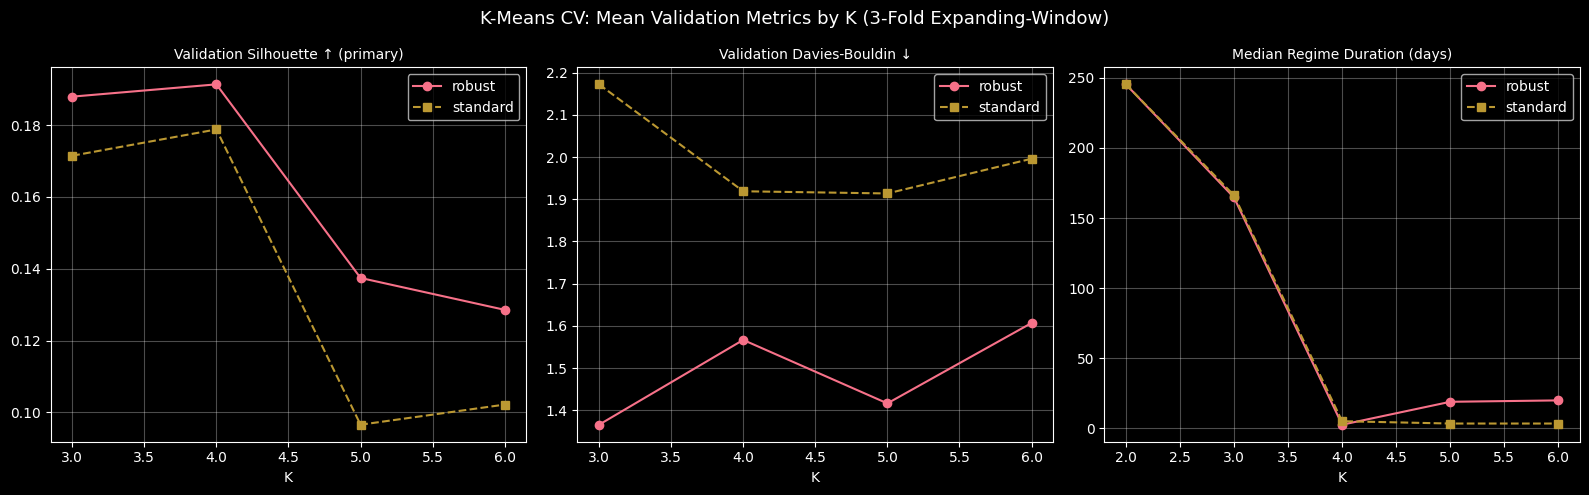

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('K-Means CV: Mean Validation Metrics by K (3-Fold Expanding-Window)', fontsize=13)

metrics = [
    ('val_silhouette', 'Validation Silhouette ↑ (primary)'),
    ('val_davies_bouldin', 'Validation Davies-Bouldin ↓'),
    ('val_median_regime_duration', 'Median Regime Duration (days)'),
]
for ax, (metric, title) in zip(axes, metrics):
    for scaler, ls in [('robust', '-o'), ('standard', '--s')]:
        grp = km_all[km_all['scaler']==scaler].groupby('k')[metric].mean()
        ax.plot(grp.index, grp.values, ls, label=scaler)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('K')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(results_dir / 'kmeans_cv_metrics.png', dpi=120, bbox_inches='tight')
plt.show()

## 3. GMM Cross-Validation

**Primary metric:** Mean validation log-likelihood per observation (higher = better generalization).  
**Supporting (diagnostic only):** Training BIC, training AIC — not used for K selection.  
**Covariance type:** Probed once on Fold 3 (`full` → `diag` → `tied`), fixed for all K and folds.  
**Settings:** `reg_covar=1e-6`, `n_init=10`, `max_iter=500`

> **Note on K=2 and entropy:** GMM with `full` covariance and 42 features on 529 training observations
> creates one large cluster (~94% of data) and one small crash cluster (~6%). The small component's
> weight approaches a degenerate point mass, so posterior probabilities saturate to near 1.0 everywhere.
> Posterior entropy is functionally zero — GMM K=2 is near-degenerate. K=3+ is more meaningful.

In [5]:
print('Running GMM CV (robust)...')
gmm_rob, cov_rob = run_gmm_cv(folds, scaler_type='robust')
print(f'Covariance type (robust): {cov_rob}')

print('Running GMM CV (standard)...')
gmm_std, cov_std = run_gmm_cv(folds, scaler_type='standard')
print(f'Covariance type (standard): {cov_std}')

gmm_all = pd.concat([gmm_rob, gmm_std], ignore_index=True)
gmm_all.to_csv(results_dir / 'gmm_cv_metrics.csv', index=False)

print('\nMean validation LL/obs by K (converged folds):')
conv = gmm_all[gmm_all['converged']]
ll_summary = conv.groupby(['scaler','k'])['val_ll_per_obs'].mean().unstack('scaler').round(4)
print(ll_summary.to_string())

k_gmm_rob = select_gmm_k(gmm_all, 'robust')
k_gmm_std = select_gmm_k(gmm_all, 'standard')
print(f'\nSelected K (robust)  : {k_gmm_rob}')
print(f'Selected K (standard): {k_gmm_std}')

Running GMM CV (robust)...
Covariance type (robust): full
Running GMM CV (standard)...
Covariance type (standard): full

Mean validation LL/obs by K (converged folds):
scaler    robust  standard
k                         
2        21.4675    7.1046
3       -26.8871   -8.8604
4       -77.1316  -51.8228
5       -93.5642  -84.0297
6      -182.5183 -214.5455

Selected K (robust)  : 2
Selected K (standard): 2


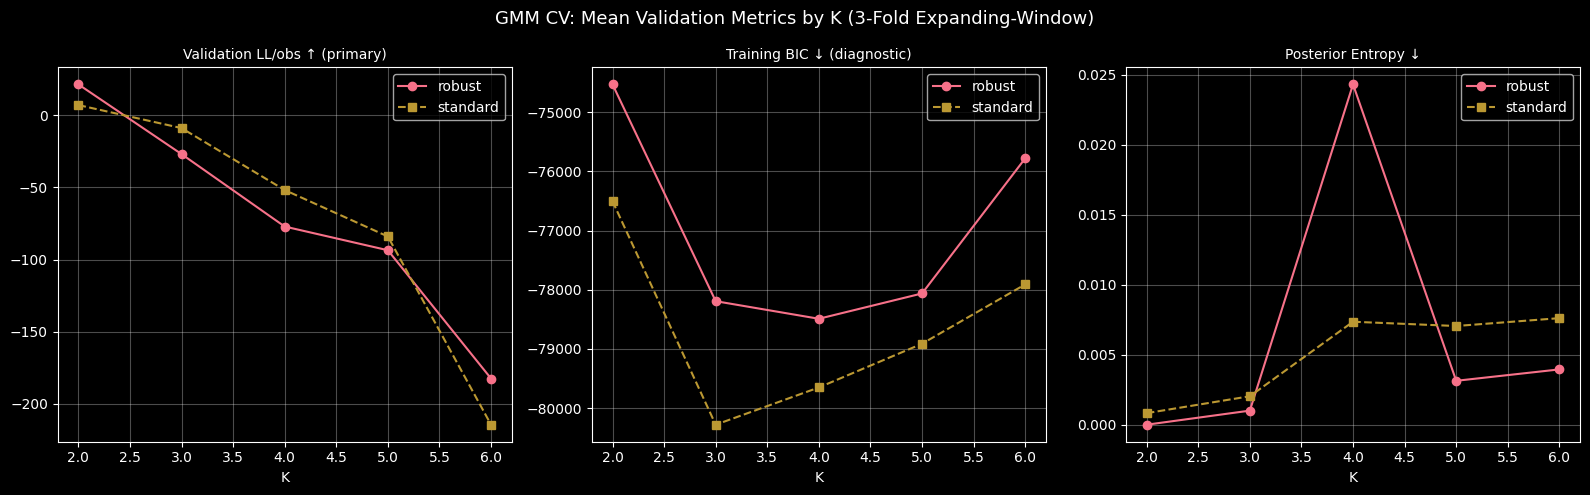

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('GMM CV: Mean Validation Metrics by K (3-Fold Expanding-Window)', fontsize=13)

for ax, (metric, title) in zip(axes, [
    ('val_ll_per_obs', 'Validation LL/obs ↑ (primary)'),
    ('train_bic', 'Training BIC ↓ (diagnostic)'),
    ('val_posterior_entropy', 'Posterior Entropy ↓'),
]):
    for scaler, ls in [('robust', '-o'), ('standard', '--s')]:
        grp = gmm_all[(gmm_all['scaler']==scaler) & gmm_all['converged']].groupby('k')[metric].mean()
        ax.plot(grp.index, grp.values, ls, label=scaler)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('K')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(results_dir / 'gmm_cv_metrics.png', dpi=120, bbox_inches='tight')
plt.show()

## 4. HMM Cross-Validation

**Primary metric:** Mean validation log-likelihood per observation (causal — forward algorithm only).  
**Settings:** `GaussianHMM`, `covariance_type='diag'`, `n_iter=200`, `tol=1e-4`, seeds 0–9.  
**Critical constraint:** Observations remain **in chronological order** — never shuffled.  
**Tie rule:** Scores within 0.01 nats → prefer smaller K.

> **Viterbi columns** in the CV table are for diagnostics only (regime duration, persistence).  
> They use the full sequence bidirectionally and are **not used for K selection** and  
> **not presented as real-time signals**.

In [7]:
print('Running HMM CV (robust) — 10 seeds x 5 K x 3 folds = 150 fits...')
hmm_rob = run_hmm_cv(folds, scaler_type='robust')
print('Running HMM CV (standard)...')
hmm_std = run_hmm_cv(folds, scaler_type='standard')
hmm_all = pd.concat([hmm_rob, hmm_std], ignore_index=True)
hmm_all.to_csv(results_dir / 'hmm_cv_metrics.csv', index=False)

print('\nRobust: mean validation LL/obs by K:')
print(hmm_rob.groupby('k')['val_ll_per_obs'].mean().round(4).to_string())
print('\nRobust: convergence rate (mean seeds converged/10):')
print(hmm_rob.groupby('k')['n_seeds_converged'].mean().round(1).to_string())
print('\nRobust: transition diagonal mean (persistence indicator):')
print(hmm_rob.groupby('k')['transition_diag_mean'].mean().round(4).to_string())

k_hmm_rob = select_hmm_k(hmm_all, 'robust')
k_hmm_std = select_hmm_k(hmm_all, 'standard')
print(f'\nSelected K (robust)  : {k_hmm_rob}')
print(f'Selected K (standard): {k_hmm_std}')

Model is not converging.  Current: -23843.90512665561 is not greater than -23843.905122485812. Delta is -4.169796739006415e-06


Model is not converging.  Current: -23843.905126656096 is not greater than -23843.905126564976. Delta is -9.112045518122613e-08
Model is not converging.  Current: -23843.905126655376 is not greater than -23843.90512288358. Delta is -3.7717945815529674e-06
Model is not converging.  Current: -23843.90512665611 is not greater than -23843.905126605496. Delta is -5.0615199143067e-08
Model is not converging.  Current: -23843.905126656093 is not greater than -23843.905126605532. Delta is -5.0560629460960627e-08
Model is not converging.  Current: -23843.905126655496 is not greater than -23843.90512248869. Delta is -4.166806320426986e-06
Model is not converging.  Current: -23843.905126656093 is not greater than -23843.905126599195. Delta is -5.689798854291439e-08
Model is not converging.  Current: -23843.905126655573 is not greater than -23843.905122530065. Delta is -4.1255079850088805e-06
Model is not converging.  Current: -23843.905126656082 is not greater than -23843.90512660531. Delta is -5

Running HMM CV (robust) — 10 seeds x 5 K x 3 folds = 150 fits...


Model is not converging.  Current: -22646.28689368077 is not greater than -22646.286893644367. Delta is -3.640525392256677e-08
Model is not converging.  Current: -19739.96454212199 is not greater than -19739.964540889698. Delta is -1.232292561326176e-06
Model is not converging.  Current: -19704.44957936177 is not greater than -19704.449578346368. Delta is -1.0154035408049822e-06
Model is not converging.  Current: -18828.432681366645 is not greater than -18828.432680151072. Delta is -1.2155724107287824e-06
Model is not converging.  Current: -18842.95820294095 is not greater than -18842.9582009295. Delta is -2.0114493963774294e-06
Model is not converging.  Current: -18842.958202531525 is not greater than -18842.95820245112. Delta is -8.040660759434104e-08
Model is not converging.  Current: -17341.794068089217 is not greater than -17341.793975077868. Delta is -9.301134923589416e-05
Model is not converging.  Current: -22730.648237028836 is not greater than -22730.648237002377. Delta is -2.

Running HMM CV (standard)...


Model is not converging.  Current: -17400.369947892716 is not greater than -17400.369929098924. Delta is -1.8793791241478175e-05
Model is not converging.  Current: -17234.056643382653 is not greater than -17234.05663574587. Delta is -7.636783266207203e-06
Model is not converging.  Current: -17226.42522679781 is not greater than -17226.425214348743. Delta is -1.2449068890418857e-05
Model is not converging.  Current: -16366.445906309447 is not greater than -16366.445903803091. Delta is -2.506356395315379e-06
Model is not converging.  Current: -16366.445906440194 is not greater than -16366.44590292325. Delta is -3.516945071169175e-06
Model is not converging.  Current: -16366.445906591733 is not greater than -16366.445900886234. Delta is -5.705498551833443e-06
Model is not converging.  Current: -36050.4643507335 is not greater than -36050.46433283331. Delta is -1.7900187231134623e-05
Model is not converging.  Current: -36050.464350733506 is not greater than -36050.46433283321. Delta is -1.


Robust: mean validation LL/obs by K:
k
2   -11022.1772
3   -10819.7292
4   -11097.6408
5   -10673.5098
6   -10319.3574

Robust: convergence rate (mean seeds converged/10):
k
2    10.0
3    10.0
4    10.0
5    10.0
6    10.0

Robust: transition diagonal mean (persistence indicator):
k
2    0.9922
3    0.9830
4    0.9800
5    0.9768
6    0.9697

Selected K (robust)  : 6
Selected K (standard): 6


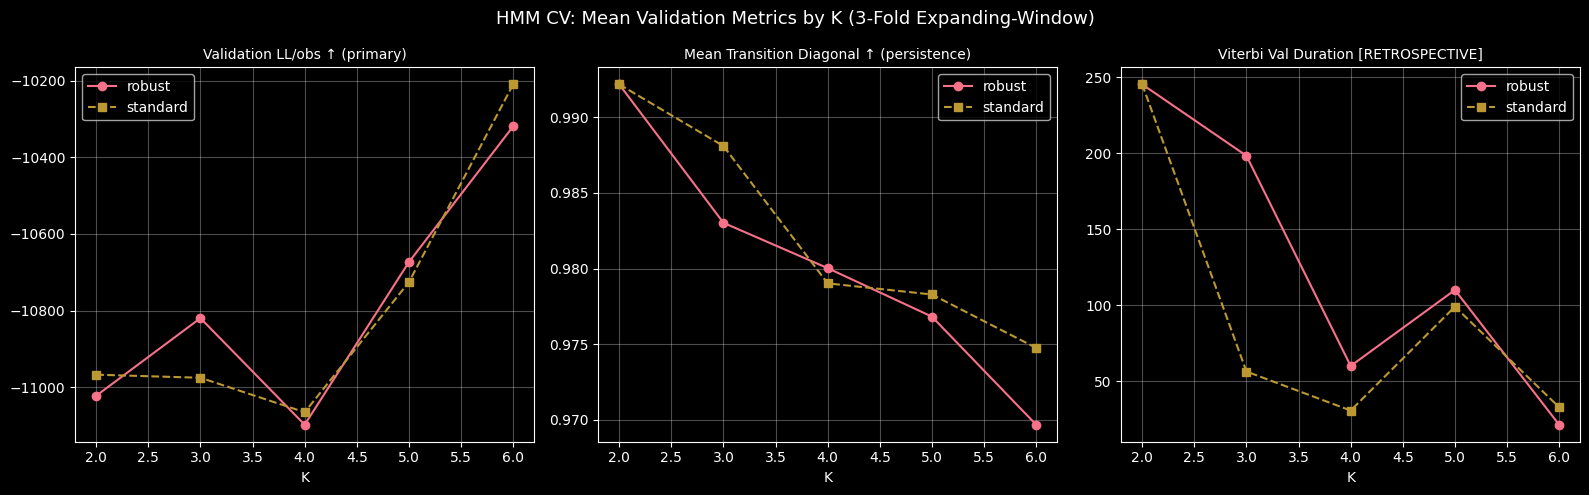

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('HMM CV: Mean Validation Metrics by K (3-Fold Expanding-Window)', fontsize=13)

for ax, (metric, title) in zip(axes, [
    ('val_ll_per_obs', 'Validation LL/obs ↑ (primary)'),
    ('transition_diag_mean', 'Mean Transition Diagonal ↑ (persistence)'),
    ('viterbi_val_median_duration_retrospective', 'Viterbi Val Duration [RETROSPECTIVE]'),
]):
    for scaler, ls in [('robust', '-o'), ('standard', '--s')]:
        grp = hmm_all[hmm_all['scaler']==scaler].groupby('k')[metric].mean()
        ax.plot(grp.index, grp.values, ls, label=scaler)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('K')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(results_dir / 'hmm_cv_metrics.png', dpi=120, bbox_inches='tight')
plt.show()

## 5. Final Model Fitting

Selected K values are refitted on the **complete clean training pool** (2019-10-31 → 2024-12-31, 1,265 rows).  
The scaler is also refit on the same pool. No holdout data is involved.

In [9]:
print('Fitting final scalers on full training pool...')
X_tr_sc_rob, final_scaler_rob = fit_scale_full(train_pool, 'robust')
X_tr_sc_std, final_scaler_std = fit_scale_full(train_pool, 'standard')

print(f'\nFitting K-Means (K={k_km_rob}, robust)...')
km_final_rob    = fit_final_kmeans(X_tr_sc_rob, k_km_rob)
km_labels_train = assign_labels_kmeans(km_final_rob, X_tr_sc_rob)
print(f'  Inertia: {km_final_rob.inertia_:.2f}')
print(f'  Label distribution: {np.bincount(km_labels_train)}')

print(f'\nFitting GMM (K={k_gmm_rob}, cov={cov_rob}, robust)...')
gmm_final_rob    = fit_final_gmm(X_tr_sc_rob, k_gmm_rob, cov_rob)
gmm_labels_train = assign_labels_gmm(gmm_final_rob, X_tr_sc_rob)
print(f'  Converged: {gmm_final_rob.converged_}')
print(f'  Train LL/obs: {gmm_final_rob.score(X_tr_sc_rob):.4f}')
print(f'  Label distribution: {np.bincount(gmm_labels_train)}')

print(f'\nFitting HMM (K={k_hmm_rob}, diag, 10 seeds)...')
hmm_final_rob, hmm_diag = fit_final_hmm(X_tr_sc_rob, k_hmm_rob)
if hmm_final_rob is not None:
    hmm_viterbi_train        = assign_viterbi_labels_hmm(hmm_final_rob, X_tr_sc_rob)
    hmm_filtered_train       = assign_filtered_proba_hmm(hmm_final_rob, X_tr_sc_rob)
    hmm_filtered_labels_train = np.argmax(hmm_filtered_train, axis=1)
    print(f'  Seeds converged: {hmm_diag["n_seeds_converged"]}/10')
    print(f'  Best train LL/obs: {hmm_diag["best_train_ll"]:.4f}')
    print(f'  Transmat diagonal mean: {hmm_diag["transmat_diag_mean"]:.4f}')
    print(f'  Stationary dist: {[round(x,3) for x in hmm_diag["stationary_dist"]]}')
    print(f'  Viterbi label dist [RETROSPECTIVE]: {np.bincount(hmm_viterbi_train)}')
    print(f'  Filtered median duration [CAUSAL]: {median_regime_duration(hmm_filtered_labels_train):.1f} days')
else:
    print('WARNING: HMM final fit did not converge.')

Fitting final scalers on full training pool...

Fitting K-Means (K=3, robust)...
  Inertia: 30507.74
  Label distribution: [323 880  62]

Fitting GMM (K=2, cov=full, robust)...
  Converged: True
  Train LL/obs: 51.7893
  Label distribution: [1201   64]

Fitting HMM (K=6, diag, 10 seeds)...
  Seeds converged: 10/10
  Best train LL/obs: -45679.3817
  Transmat diagonal mean: 0.9707
  Stationary dist: [0.192, 0.031, 0.328, 0.021, 0.272, 0.156]
  Viterbi label dist [RETROSPECTIVE]: [246  40 395  27 359 198]
  Filtered median duration [CAUSAL]: 21.0 days


## 6. Holdout Evaluation (2025–2026)

> **Lockbox rule:** Results from this section do **not** modify K, covariance type,
> or any hyperparameter. This section is executed exactly once, after all configurations are fixed.

For HMM: both Viterbi (retrospective — full sequence) and forward-filtered (causal — past only)
labels are produced and kept **clearly distinct** in all subsequent outputs.

In [10]:
print('=== HOLDOUT EVALUATION — executed once after K selection finalized ===')
print(f'Period: {holdout.index.min().date()} to {holdout.index.max().date()}  ({len(holdout)} rows)\n')

ho_km  = evaluate_holdout('kmeans', km_final_rob, final_scaler_rob, holdout, k_km_rob,  'robust')
ho_gmm = evaluate_holdout('gmm',    gmm_final_rob, final_scaler_rob, holdout, k_gmm_rob, 'robust')

print(f'K-Means (K={k_km_rob}):')
print(f'  Silhouette   : {ho_km["val_silhouette"]:.4f}')
print(f'  Median dur   : {ho_km["median_duration"]:.1f} days')
print(f'  Label dist   : {np.bincount(ho_km["labels"], minlength=k_km_rob)}')

print(f'\nGMM (K={k_gmm_rob}, {cov_rob}):')
print(f'  LL/obs       : {ho_gmm["ll_per_obs"]:.4f}')
print(f'  Post entropy : {ho_gmm["posterior_entropy"]:.6f}')
print(f'  Median dur   : {ho_gmm["median_duration"]:.1f} days')
print(f'  Label dist   : {np.bincount(ho_gmm["labels"], minlength=k_gmm_rob)}')

if hmm_final_rob is not None:
    ho_hmm = evaluate_holdout('hmm', hmm_final_rob, final_scaler_rob, holdout, k_hmm_rob, 'robust')
    print(f'\nHMM (K={k_hmm_rob}, diag):')
    print(f'  LL/obs             : {ho_hmm["ll_per_obs"]:.4f}')
    print(f'  Viterbi dur [RETROSPECTIVE]: {ho_hmm["viterbi_median_duration_retrospective"]:.1f} days')
    print(f'  Filtered dur [CAUSAL]      : {ho_hmm["filtered_median_duration_causal"]:.1f} days')
    print(f'  Viterbi label dist [RETROSPECTIVE]: {np.bincount(ho_hmm["viterbi_labels_retrospective"], minlength=k_hmm_rob)}')
    print(f'  Filtered label dist [CAUSAL]      : {np.bincount(ho_hmm["filtered_labels_causal"], minlength=k_hmm_rob)}')
else:
    ho_hmm = None

=== HOLDOUT EVALUATION — executed once after K selection finalized ===
Period: 2025-01-02 to 2026-09-18  (422 rows)

K-Means (K=3):
  Silhouette   : 0.1990
  Median dur   : 2.0 days
  Label dist   : [ 33 389   0]

GMM (K=2, full):
  LL/obs       : 39.2416
  Post entropy : -0.000000
  Median dur   : 422.0 days
  Label dist   : [422   0]

HMM (K=6, diag):
  LL/obs             : -16858.3740
  Viterbi dur [RETROSPECTIVE]: 15.0 days
  Filtered dur [CAUSAL]      : 12.0 days
  Viterbi label dist [RETROSPECTIVE]: [  5   0 118   0 175 124]
  Filtered label dist [CAUSAL]      : [  8   0 118   0 170 126]


## 7. Final Regime Labels — Save CSV

In [11]:
label_rows = []

def _add_rows(dates, labels, period, model, k, label_type):
    for d, lbl in zip(dates, labels):
        label_rows.append({'Date': d, 'period': period, 'model': model,
                            'scaler': 'robust', 'k': k,
                            'regime_id': int(lbl), 'label_type': label_type})

_add_rows(train_pool.index, km_labels_train,  'train',   'kmeans', k_km_rob,  'hard')
_add_rows(train_pool.index, gmm_labels_train, 'train',   'gmm',    k_gmm_rob, 'hard')
_add_rows(holdout.index,    ho_km['labels'],  'holdout', 'kmeans', k_km_rob,  'hard')
_add_rows(holdout.index,    ho_gmm['labels'], 'holdout', 'gmm',    k_gmm_rob, 'hard')

if hmm_final_rob is not None:
    _add_rows(train_pool.index, hmm_viterbi_train,         'train',   'hmm', k_hmm_rob, 'retrospective_viterbi')
    _add_rows(train_pool.index, hmm_filtered_labels_train, 'train',   'hmm', k_hmm_rob, 'filtered_causal')
if ho_hmm is not None:
    _add_rows(holdout.index, ho_hmm['viterbi_labels_retrospective'], 'holdout', 'hmm', k_hmm_rob, 'retrospective_viterbi')
    _add_rows(holdout.index, ho_hmm['filtered_labels_causal'],       'holdout', 'hmm', k_hmm_rob, 'filtered_causal')

labels_df = pd.DataFrame(label_rows)
labels_df.to_csv(results_dir / 'final_regime_labels.csv', index=False)
print(f'Saved: results/final_regime_labels.csv  ({len(labels_df)} rows)')
print(labels_df.groupby(['model','label_type','period'])['regime_id'].count().to_string())

Saved: results/final_regime_labels.csv  (6748 rows)
model   label_type             period 
gmm     hard                   holdout     422
                               train      1265
hmm     filtered_causal        holdout     422
                               train      1265
        retrospective_viterbi  holdout     422
                               train      1265
kmeans  hard                   holdout     422
                               train      1265


## 8. Regime Characterisation

Statistics computed on the **original unscaled features** — no scaling contamination.  
Regime IDs are integers only; economic interpretation is a separate manual step.

In [12]:
char_dfs = []
char_dfs.append(characterise_regimes(train_pool, km_labels_train,  'kmeans', k_km_rob,  'robust', 'hard'))
char_dfs.append(characterise_regimes(train_pool, gmm_labels_train, 'gmm',    k_gmm_rob, 'robust', 'hard'))
if hmm_final_rob is not None:
    char_dfs.append(characterise_regimes(
        train_pool, hmm_viterbi_train, 'hmm', k_hmm_rob, 'robust', 'retrospective_viterbi'))

char_df = pd.concat(char_dfs, ignore_index=True)
char_df.to_csv(results_dir / 'regime_characterisation.csv', index=False)
print(f'Saved: results/regime_characterisation.csv  ({len(char_df)} rows)')

key_features = ['Return_20D', 'Return_60D', 'NIFTY50_Market_Trend_200D', 'VIX_Close']
for model_name, lt in [('kmeans','hard'), ('gmm','hard'), ('hmm','retrospective_viterbi')]:
    sub = char_df[(char_df['model']==model_name) & (char_df['feature'].isin(key_features))]
    if sub.empty:
        continue
    pivot = sub.pivot_table(index='feature', columns='regime_id', values='mean').round(4)
    print(f'\n=== {model_name.upper()} regime means (key features) ===')
    if model_name == 'hmm':
        print('  [label_type: retrospective_viterbi]')
    print(pivot.to_string())

Saved: results/regime_characterisation.csv  (462 rows)

=== KMEANS regime means (key features) ===
regime_id                        0        1        2
feature                                             
NIFTY50_Market_Trend_200D   1.1201   1.0590   0.8182
Return_20D                  0.0458   0.0057  -0.0446
Return_60D                  0.1202   0.0327  -0.2252
VIX_Close                  20.5283  15.4002  44.7347

=== GMM regime means (key features) ===
regime_id                        0        1
feature                                    
NIFTY50_Market_Trend_200D   1.0757   0.8210
Return_20D                  0.0163  -0.0395
Return_60D                  0.0562  -0.2154
VIX_Close                  16.7498  44.3730

=== HMM regime means (key features) ===
  [label_type: retrospective_viterbi]
regime_id                        0        1        2        3        4        5
feature                                                                        
NIFTY50_Market_Trend_200D   1.1409   0.

## 9. Regime Timeline Plots

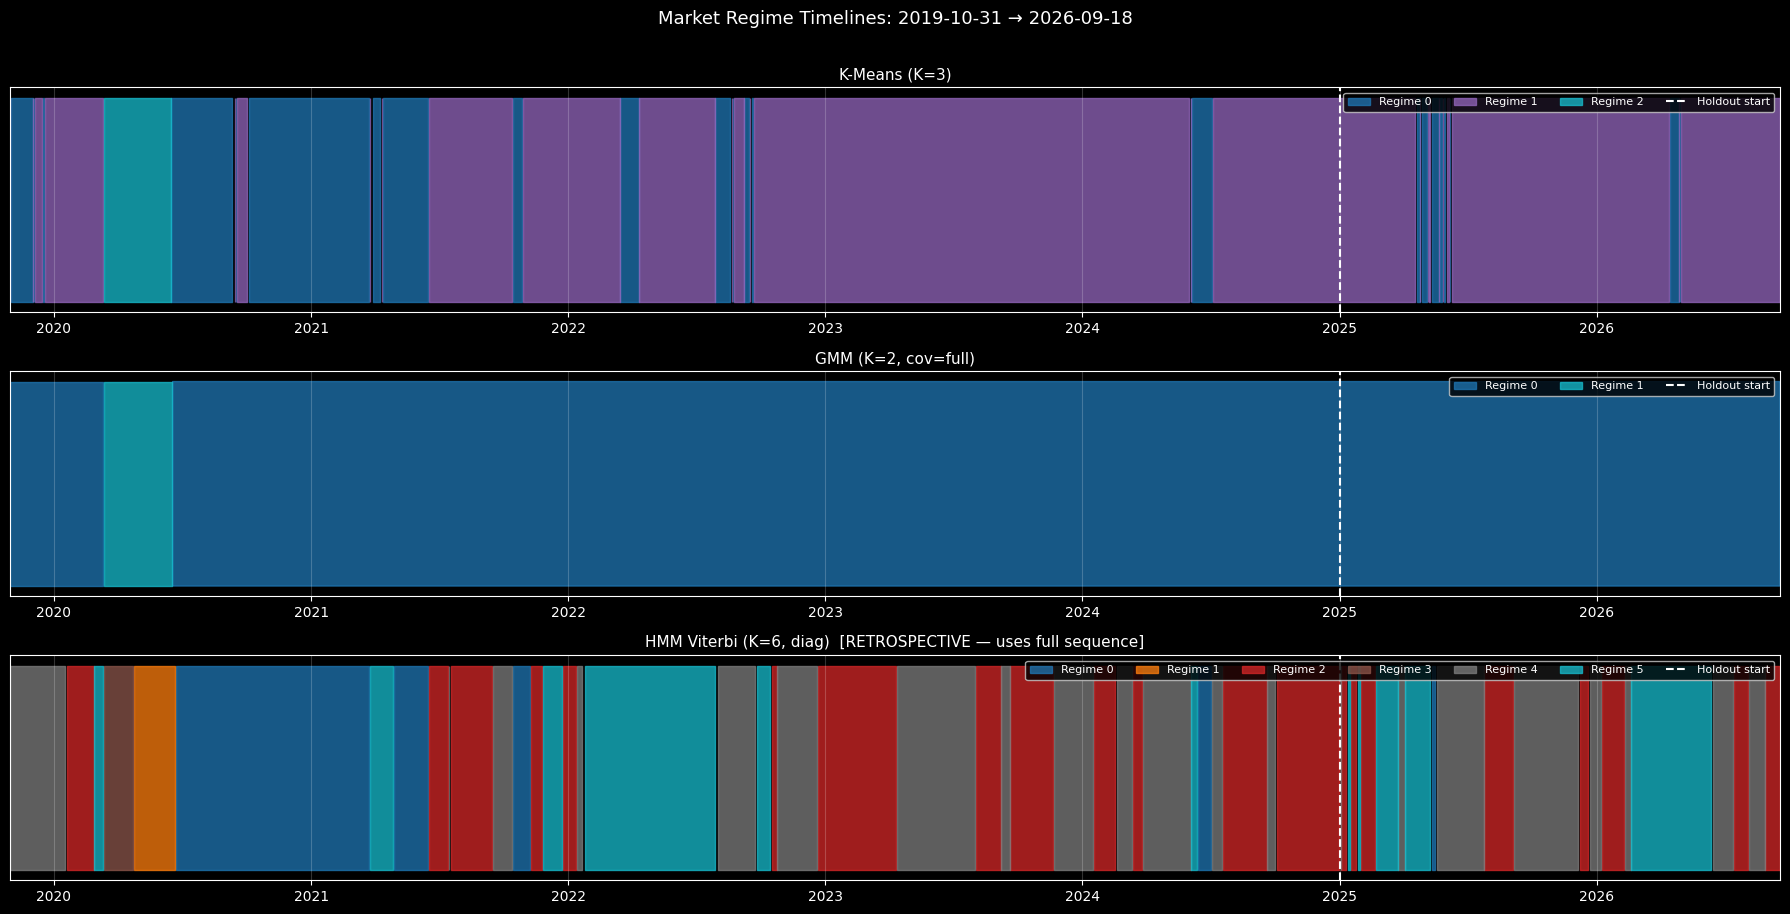

In [13]:
all_dates = train_pool.index.append(holdout.index)
km_all_labels  = np.concatenate([km_labels_train, ho_km['labels']])
gmm_all_labels = np.concatenate([gmm_labels_train, ho_gmm['labels']])

n_rows = 2 + (1 if hmm_final_rob is not None else 0)
fig, axes = plt.subplots(n_rows, 1, figsize=(18, 3*n_rows))
cmap = plt.cm.tab10

def draw_timeline(ax, dates, labels, k, title):
    colors = cmap(np.linspace(0, 0.9, k))
    for r in range(k):
        mask = labels == r
        ax.fill_between(dates, 0, 1, where=mask, alpha=0.75, color=colors[r], label=f'Regime {r}')
    ax.axvline(pd.Timestamp('2025-01-01'), color='white', lw=1.5, linestyle='--', label='Holdout start')
    ax.set_yticks([])
    ax.set_title(title, fontsize=11)
    ax.legend(loc='upper right', fontsize=8, ncol=k+1)
    ax.set_xlim(dates.min(), dates.max())
    ax.grid(axis='x', alpha=0.2)

draw_timeline(axes[0], all_dates, km_all_labels,  k_km_rob,  f'K-Means (K={k_km_rob})')
draw_timeline(axes[1], all_dates, gmm_all_labels, k_gmm_rob, f'GMM (K={k_gmm_rob}, cov={cov_rob})')

if hmm_final_rob is not None:
    hmm_viterbi_all = np.concatenate([hmm_viterbi_train, ho_hmm['viterbi_labels_retrospective']])
    draw_timeline(axes[2], all_dates, hmm_viterbi_all, k_hmm_rob,
                  f'HMM Viterbi (K={k_hmm_rob}, diag)  [RETROSPECTIVE — uses full sequence]')

fig.suptitle('Market Regime Timelines: 2019-10-31 → 2026-09-18', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(results_dir / 'regime_timelines.png', dpi=120, bbox_inches='tight')
plt.show()

### 9b. HMM: Filtered (Causal) vs Viterbi (Retrospective)

Forward-filtered probabilities show what a real-time system would observe.  
Viterbi is shown for comparison only — it uses future data.

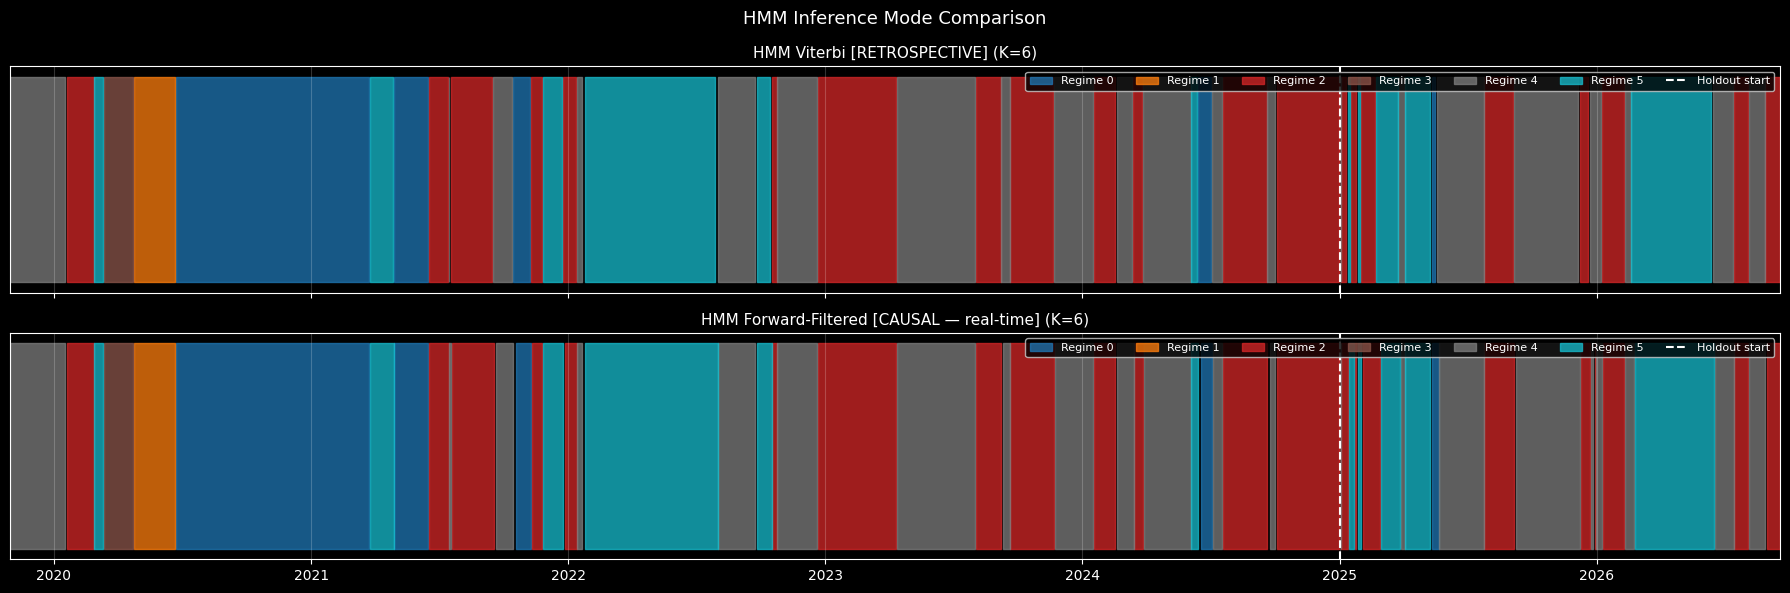

In [14]:
if hmm_final_rob is not None:
    hmm_filt_all = np.concatenate([hmm_filtered_labels_train, ho_hmm['filtered_labels_causal']])

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 6), sharex=True)
    draw_timeline(ax1, all_dates, hmm_viterbi_all, k_hmm_rob,
                  f'HMM Viterbi [RETROSPECTIVE] (K={k_hmm_rob})')
    draw_timeline(ax2, all_dates, hmm_filt_all,    k_hmm_rob,
                  f'HMM Forward-Filtered [CAUSAL — real-time] (K={k_hmm_rob})')
    plt.suptitle('HMM Inference Mode Comparison', fontsize=13)
    plt.tight_layout()
    plt.savefig(results_dir / 'hmm_causal_vs_retrospective.png', dpi=120, bbox_inches='tight')
    plt.show()

## 10. HMM Transition Matrix and Stationary Distribution

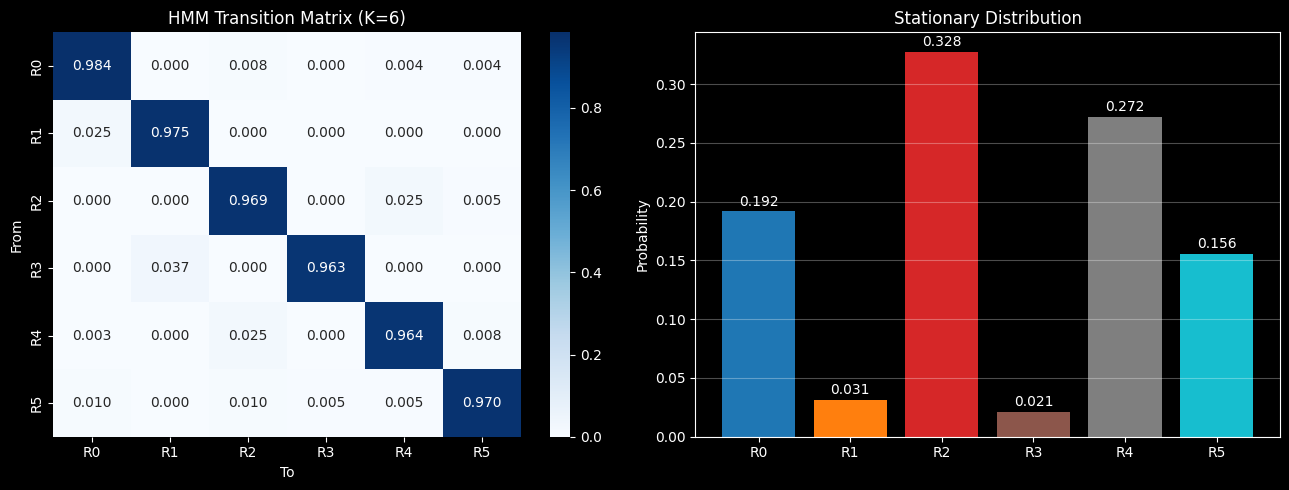

Transmat diagonal mean (regime persistence): 0.9707
Min stationary mass: 0.0212   (should be > 0.02)


In [15]:
if hmm_final_rob is not None:
    trans = np.array(hmm_diag['transition_matrix'])
    stat  = np.array(hmm_diag['stationary_dist'])

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    labels_list = [f'R{i}' for i in range(k_hmm_rob)]

    sns.heatmap(trans, annot=True, fmt='.3f', cmap='Blues', ax=axes[0],
                xticklabels=labels_list, yticklabels=labels_list)
    axes[0].set_title(f'HMM Transition Matrix (K={k_hmm_rob})')
    axes[0].set_xlabel('To')
    axes[0].set_ylabel('From')

    clrs = plt.cm.tab10(np.linspace(0, 0.9, k_hmm_rob))
    axes[1].bar(range(k_hmm_rob), stat, color=clrs)
    axes[1].set_title('Stationary Distribution')
    axes[1].set_xticks(range(k_hmm_rob))
    axes[1].set_xticklabels(labels_list)
    axes[1].set_ylabel('Probability')
    axes[1].grid(axis='y', alpha=0.3)
    for i, s in enumerate(stat):
        axes[1].text(i, s+0.005, f'{s:.3f}', ha='center', fontsize=10)

    plt.tight_layout()
    plt.savefig(results_dir / 'hmm_transition_matrix.png', dpi=120, bbox_inches='tight')
    plt.show()
    print('Transmat diagonal mean (regime persistence):', round(trans.diagonal().mean(), 4))
    print('Min stationary mass:', round(stat.min(), 4), '  (should be > 0.02)')

## 11. Scaler Sensitivity Comparison

RobustScaler (primary) vs StandardScaler. Same K candidates, same CV folds.  
ARI (Adjusted Rand Index) measures label agreement on training data (where same K was selected).  
ARI ≥ 0.60 → robust to scaler choice. ARI ≥ 0.40 → broadly consistent. Below → materially different.

In [16]:
# Refit standard-scaler final models
km_final_std   = fit_final_kmeans(X_tr_sc_std, k_km_std)
gmm_final_std  = fit_final_gmm(X_tr_sc_std, k_gmm_std, cov_std)
hmm_final_std, _ = fit_final_hmm(X_tr_sc_std, k_hmm_std)

km_labels_std  = assign_labels_kmeans(km_final_std,  X_tr_sc_std)
gmm_labels_std = assign_labels_gmm(gmm_final_std, X_tr_sc_std)

print('=== SCALER SENSITIVITY ===')
for model_name, lbl_r, lbl_s, k_r, k_s in [
    ('kmeans', km_labels_train,  km_labels_std,  k_km_rob,  k_km_std),
    ('gmm',    gmm_labels_train, gmm_labels_std, k_gmm_rob, k_gmm_std),
]:
    res = compare_scaler_sensitivity(lbl_r, lbl_s, k_r, k_s, model_name)
    ari = f'{res["ari"]:.4f}' if res['ari'] is not None and not (isinstance(res['ari'], float) and res['ari'] != res['ari']) else 'N/A'
    print(f'  {model_name.upper()}: K_robust={k_r}, K_std={k_s}, ARI={ari}, assessment={res["assessment"]}')

if hmm_final_rob is not None and hmm_final_std is not None:
    hmm_labels_std = assign_viterbi_labels_hmm(hmm_final_std, X_tr_sc_std)
    res = compare_scaler_sensitivity(hmm_viterbi_train, hmm_labels_std, k_hmm_rob, k_hmm_std, 'hmm')
    ari = f'{res["ari"]:.4f}' if 'ari' in res and res['ari'] == res['ari'] else 'N/A'
    print(f'  HMM: K_robust={k_hmm_rob}, K_std={k_hmm_std}, ARI={ari}, assessment={res["assessment"]}')
    print('  [ARI on Viterbi labels; both retrospective — for comparison only]')

=== SCALER SENSITIVITY ===
  KMEANS: K_robust=3, K_std=3, ARI=0.1575, assessment=materially_different
  GMM: K_robust=2, K_std=2, ARI=0.9816, assessment=scaler_robust
  HMM: K_robust=6, K_std=6, ARI=0.4196, assessment=broadly_consistent
  [ARI on Viterbi labels; both retrospective — for comparison only]


## 12. Phase 6 Summary and Output Verification

In [17]:
print('=== PHASE 6 OUTPUT VERIFICATION ===')
required = [
    'kmeans_cv_metrics.csv', 'gmm_cv_metrics.csv', 'hmm_cv_metrics.csv',
    'final_regime_labels.csv', 'regime_characterisation.csv',
]
all_ok = True
for fname in required:
    p = results_dir / fname
    if p.exists():
        df = pd.read_csv(p)
        print(f'  OK  {fname}  ({len(df)} rows)')
    else:
        print(f'  MISSING  {fname}')
        all_ok = False

print(f'\n=== SELECTED CONFIGURATIONS (RobustScaler primary) ===')
print(f'  K-Means : K = {k_km_rob}')
print(f'  GMM     : K = {k_gmm_rob},  covariance = {cov_rob}')
print(f'  HMM     : K = {k_hmm_rob},  covariance = diag')

print(f'\n=== DATA INTEGRITY CHECK ===')
ldf = pd.read_csv(results_dir / 'final_regime_labels.csv', parse_dates=['Date'])
tr_labels = ldf[ldf['period']=='train']
ho_labels = ldf[ldf['period']=='holdout']
assert tr_labels['Date'].max() <= pd.Timestamp('2024-12-31'), 'FAIL: train bleed!'
assert ho_labels['Date'].min() >= pd.Timestamp('2025-01-01'), 'FAIL: holdout too early!'
print('  Train/holdout boundaries: CLEAN')
print(f'  Train rows: {len(tr_labels)}, Holdout rows: {len(ho_labels)}')

print(f'\nPhase 6 complete — all outputs verified: {all_ok}')

=== PHASE 6 OUTPUT VERIFICATION ===
  OK  kmeans_cv_metrics.csv  (30 rows)
  OK  gmm_cv_metrics.csv  (30 rows)
  OK  hmm_cv_metrics.csv  (30 rows)
  OK  final_regime_labels.csv  (6748 rows)
  OK  regime_characterisation.csv  (462 rows)

=== SELECTED CONFIGURATIONS (RobustScaler primary) ===
  K-Means : K = 3
  GMM     : K = 2,  covariance = full
  HMM     : K = 6,  covariance = diag

=== DATA INTEGRITY CHECK ===
  Train/holdout boundaries: CLEAN
  Train rows: 5060, Holdout rows: 1688

Phase 6 complete — all outputs verified: True
